# Notebook 1 — Data Understanding

## Purpose

This notebook audits the synthetic Indian loan-application dataset before exploratory analysis or modeling. We will verify its structure and quality, define the 12-month default target, inspect class balance, and flag identifiers or fields that should not enter a prediction model without further validation.

**Dataset:** `data/raw/finsight_ai_india_synthetic_5000.csv`  
**Target:** `target_default_within_12m` — whether the applicant defaults within 12 months, encoded as 1 (yes) or 0 (no). The CSV contains a synthetic dataset; its generated relationships should not be treated as evidence about real borrowers or lending populations.

Each analysis section is followed by a short interpretation. No rows or columns are changed in this audit.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# Resolve the file whether the notebook is launched from the project root or notebooks/.
relative_data_path = Path("data/raw/finsight_ai_india_synthetic_5000.csv")
data_path = next(
    (candidate for candidate in (relative_data_path, Path("..") / relative_data_path) if candidate.exists()),
    None,
)
if data_path is None:
    raise FileNotFoundError(
        "Could not find data/raw/finsight_ai_india_synthetic_5000.csv. "
        "Run this notebook from the project root or notebooks/ directory."
    )

df = pd.read_csv(data_path)
target_column = "target_default_within_12m"
if target_column not in df.columns:
    raise ValueError(f"Expected target column {target_column!r} was not found.")

print(f"Dataset file: {data_path.resolve()}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes.to_string())
print("\nFirst five rows:")
display(df.head())

Dataset file: D:\GOURAB DAS\CODE\Git\FinSight AI\data\raw\finsight_ai_india_synthetic_5000.csv
Shape: 5,000 rows × 29 columns

Column names:
['application_id', 'age_years', 'state', 'city_tier', 'employment_type', 'employment_years', 'education_level', 'residence_type', 'monthly_net_income_inr', 'existing_monthly_debt_inr', 'requested_loan_amount_inr', 'loan_tenure_months', 'annual_interest_rate_pct', 'estimated_emi_inr', 'debt_to_income_after_loan', 'credit_history_years', 'open_credit_accounts', 'credit_inquiries_last_6m', 'late_payments_last_12m', 'prior_default_flag', 'credit_utilization_ratio', 'savings_balance_inr', 'banking_relationship_months', 'dependents_count', 'loan_purpose', 'repayment_method', 'target_default_within_12m', 'ead_assumption_inr', 'lgd_assumption']

Data types:
application_id                     str
age_years                        int64
state                              str
city_tier                          str
employment_type                    str
employ

,application_id,age_years,state,city_tier,employment_type,employment_years,education_level,residence_type,monthly_net_income_inr,existing_monthly_debt_inr,...,prior_default_flag,credit_utilization_ratio,savings_balance_inr,banking_relationship_months,dependents_count,loan_purpose,repayment_method,target_default_within_12m,ead_assumption_inr,lgd_assumption
0,FIN000001,28,Uttar Pradesh,Tier 2,Salaried,0.5,Diploma,Rented,32194,4878,...,0,0.2731,76252.0,147.0,6,Home improvement,Mixed,0,170103,0.411
1,FIN000002,21,Delhi NCR,Tier 1,Salaried,3.3,Graduate,Family-owned,74646,20190,...,0,0.2485,47945.0,145.0,0,Small business,UPI/autopay,0,179443,0.476
2,FIN000003,45,Delhi NCR,Tier 3/Rural,Self-employed,2.5,Postgraduate,Owned,78669,54653,...,0,0.3576,41586.0,12.0,1,Vehicle,UPI/autopay,0,135803,0.367
3,FIN000004,28,Odisha,Tier 2,Salaried,2.8,Graduate,Family-owned,29232,8837,...,0,0.3947,176097.0,198.0,3,Personal,Manual bank transfer,1,516780,0.558
4,FIN000005,25,Maharashtra,Tier 2,Salaried,3.6,Secondary,Family-owned,84036,13520,...,0,0.4426,29788.0,107.0,2,Home improvement,NACH/ECS,1,63000,0.494


The CSV loaded from the project data folder with **5,000 rows and 29 columns**. The first records and inferred data types look structurally usable, and the expected 12-month target column is present. Next, inspect the numeric ranges and categorical levels; the displayed sample is only a preview, not a basis for conclusions about the full dataset.

In [2]:
# Numeric fields get standard summary statistics; categorical fields get their distinct-value counts and examples.
numeric_summary = df.describe(include="number").T
categorical_columns = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()
categorical_summary = pd.DataFrame(
    {
        "unique_values": df[categorical_columns].nunique(dropna=False),
        "examples": [
            ", ".join(map(str, df[column].dropna().unique()[:8]))
            for column in categorical_columns
        ],
    }
)

print("Numeric summary statistics:")
display(numeric_summary.round(2))
print("Categorical value overview (at most eight examples per field):")
display(categorical_summary)

Numeric summary statistics:


,count,mean,std,min,25%,50%,75%,max
age_years,5000.0,42.88,12.83,21.00,32.00,43.00,54.00,65.00
employment_years,4816.0,6.57,5.01,0.00,2.90,5.50,9.02,40.00
monthly_net_income_inr,5000.0,48507.10,33904.72,5000.00,25912.50,40177.50,61397.00,398564.00
existing_monthly_debt_inr,5000.0,16063.20,15541.19,70.00,5948.00,11440.00,20891.00,192706.00
requested_loan_amount_inr,5000.0,288349.28,236421.06,17775.00,132858.75,219347.50,366811.00,2500000.00
loan_tenure_months,5000.0,32.19,16.53,6.00,18.00,36.00,48.00,60.00
annual_interest_rate_pct,5000.0,16.63,4.98,7.50,13.00,16.56,20.00,36.00
estimated_emi_inr,5000.0,15561.64,18676.59,372.00,5232.75,9666.00,18445.75,300394.00
debt_to_income_after_loan,5000.0,0.84,0.96,0.05,0.42,0.63,0.93,27.73
credit_history_years,4776.0,3.86,2.66,0.10,1.90,3.30,5.10,21.00


Categorical value overview (at most eight examples per field):


,unique_values,examples
application_id,5000,"FIN000001, FIN000002, FIN000003, FIN000004, FI..."
state,16,"Uttar Pradesh, Delhi NCR, Odisha, Maharashtra,..."
city_tier,3,"Tier 2, Tier 1, Tier 3/Rural"
employment_type,6,"Salaried, Self-employed, Business owner, Agric..."
education_level,7,"Diploma, Graduate, Postgraduate, Secondary, Hi..."
residence_type,5,"Rented, Family-owned, Owned, Employer-provided..."
loan_purpose,8,"Home improvement, Small business, Vehicle, Per..."
repayment_method,6,"Mixed, UPI/autopay, Manual bank transfer, NACH..."


### What the schema tells us

The file loaded successfully with 5,000 application records and 29 columns. It combines numeric borrower and loan attributes with eight text fields; `application_id` is unique-looking and should be treated as an identifier, not a model feature. Numeric summaries show some missing values and a debt-to-income maximum above 1, so completeness and domain checks are needed before modeling. `ead_assumption_inr` currently has the same summary statistics as requested loan amount, which merits a direct equality check before deciding how to use it.

In [3]:
missing_summary = (
    df.isna()
    .sum()
    .rename("missing_rows")
    .to_frame()
    .assign(missing_percent=lambda table: 100 * table["missing_rows"] / len(df))
    .query("missing_rows > 0")
    .sort_values("missing_rows", ascending=False)
)
duplicate_rows = int(df.duplicated().sum())
duplicate_ids = int(df["application_id"].duplicated().sum())

print(f"Rows with at least one missing field: {df.isna().any(axis=1).sum():,} of {len(df):,}")
print("Missing values by column:")
display(missing_summary)
print(f"Exact duplicate rows: {duplicate_rows:,}")
print(f"Repeated application IDs after the first occurrence: {duplicate_ids:,}")

Rows with at least one missing field: 974 of 5,000
Missing values by column:


,missing_rows,missing_percent
credit_history_years,224,4.48
credit_utilization_ratio,211,4.22
employment_years,184,3.68
savings_balance_inr,152,3.04
education_level,145,2.90
banking_relationship_months,93,1.86
repayment_method,77,1.54


Exact duplicate rows: 0
Repeated application IDs after the first occurrence: 0


### Completeness and duplicate records

Missing values are concentrated in seven fields, led by `credit_history_years` (4.48%) and `credit_utilization_ratio` (4.22%); 974 rows (19.48%) have at least one missing field. The target and identifier are complete. There are no exact duplicate rows or repeated application IDs. Keep the records for now: assess missingness by feature and choose training-time imputation or explicit missing indicators later, rather than deleting otherwise useful applications during this audit.

In [4]:
# Treat this as a binary outcome only after confirming that every observed value is 0 or 1.
target_values = set(df[target_column].dropna().unique())
invalid_target_rows = int((~df[target_column].isin([0, 1])).sum())
target_counts = df[target_column].value_counts(dropna=False).sort_index()
target_distribution = pd.DataFrame(
    {
        "applications": target_counts,
        "percent": (target_counts / len(df) * 100).round(2),
    }
)

print("Target definition: 1 = default within 12 months; 0 = no default within 12 months.")
print(f"Observed target values: {sorted(target_values)}")
print(f"Missing target values: {int(df[target_column].isna().sum()):,}")
print(f"Rows with target values outside {{0, 1}}: {invalid_target_rows:,}")
display(target_distribution.rename(index={0: "No default (0)", 1: "Default (1)"}))

Target definition: 1 = default within 12 months; 0 = no default within 12 months.
Observed target values: [np.int64(0), np.int64(1)]
Missing target values: 0
Rows with target values outside {0, 1}: 0


,applications,percent
target_default_within_12m,,
No default (0),3616,72.32
Default (1),1384,27.68


### Target definition and class balance

The target is complete and contains only the expected binary values: **1 means default within 12 months; 0 means no default within 12 months**. There are 1,384 positive cases (27.68%) and 3,616 negative cases (72.32%). This is a moderately imbalanced classification target, not a balanced sample; later model evaluation should not rely on accuracy alone. The target definition is the meaning supplied by the dataset column name, not an independently verified real-world event definition.

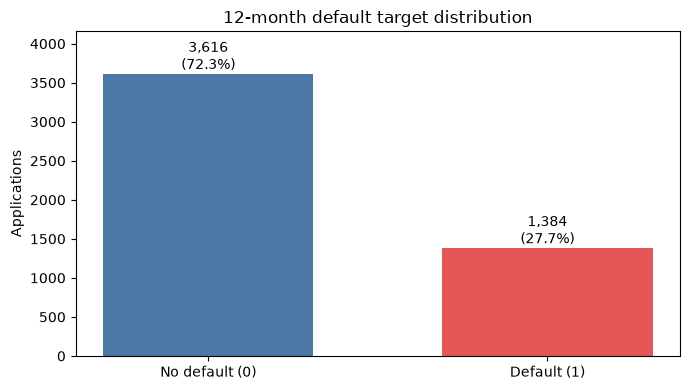

In [5]:
import matplotlib.pyplot as plt

class_labels = ["No default (0)", "Default (1)"]
class_values = [int(target_counts.get(0, 0)), int(target_counts.get(1, 0))]
class_colors = ["#4C78A8", "#E45756"]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(class_labels, class_values, color=class_colors, width=0.62)
ax.set_title("12-month default target distribution")
ax.set_ylabel("Applications")
ax.set_ylim(0, max(class_values) * 1.15)
for bar, value in zip(bars, class_values):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:,}\n({value / len(df):.1%})", ha="center", va="bottom")
fig.tight_layout()
plt.show()

The bar chart makes the class imbalance visible: the non-default class is larger, but defaults still represent more than one quarter of this synthetic sample. Preserve this prevalence when splitting the data and report class-sensitive metrics such as recall, precision, and PR-AUC in the modeling notebook.

In [6]:
# These checks flag values that conflict with field meaning; they do not silently edit or remove rows.
domain_rules = {
    "age_years (adult applicant, 18–100)": df["age_years"].lt(18) | df["age_years"].gt(100),
    "employment_years (negative or greater than age)": (
        df["employment_years"].lt(0) | df["employment_years"].gt(df["age_years"])
    ),
    "monthly_net_income_inr (must be positive)": df["monthly_net_income_inr"].le(0),
    "existing_monthly_debt_inr (must be non-negative)": df["existing_monthly_debt_inr"].lt(0),
    "requested_loan_amount_inr (must be positive)": df["requested_loan_amount_inr"].le(0),
    "loan_tenure_months (must be positive)": df["loan_tenure_months"].le(0),
    "annual_interest_rate_pct (outside 0–100)": (
        df["annual_interest_rate_pct"].lt(0) | df["annual_interest_rate_pct"].gt(100)
    ),
    "estimated_emi_inr (must be non-negative)": df["estimated_emi_inr"].lt(0),
    "debt_to_income_after_loan (negative ratio)": df["debt_to_income_after_loan"].lt(0),
    "credit_history_years (negative or greater than age)": (
        df["credit_history_years"].lt(0) | df["credit_history_years"].gt(df["age_years"])
    ),
    "open_credit_accounts (negative count)": df["open_credit_accounts"].lt(0),
    "credit_inquiries_last_6m (negative count)": df["credit_inquiries_last_6m"].lt(0),
    "late_payments_last_12m (negative count)": df["late_payments_last_12m"].lt(0),
    "prior_default_flag (not binary)": ~df["prior_default_flag"].isin([0, 1]),
    "credit_utilization_ratio (outside conventional 0–1 range)": (
        df["credit_utilization_ratio"].lt(0) | df["credit_utilization_ratio"].gt(1)
    ),
    "savings_balance_inr (negative balance)": df["savings_balance_inr"].lt(0),
    "banking_relationship_months (negative duration)": df["banking_relationship_months"].lt(0),
    "dependents_count (negative count)": df["dependents_count"].lt(0),
    "ead_assumption_inr (must be positive)": df["ead_assumption_inr"].le(0),
    "lgd_assumption (outside 0–1)": (
        df["lgd_assumption"].lt(0) | df["lgd_assumption"].gt(1)
    ),
}
domain_review = pd.DataFrame(
    {
        "flagged_rows": {name: int(mask.sum()) for name, mask in domain_rules.items()},
        "example_values": {
            name: ", ".join(map(str, df.loc[mask, name.split(" (")[0]].head(3).tolist()))
            for name, mask in domain_rules.items()
        },
    }
).query("flagged_rows > 0")

categorical_review = {}
for column in categorical_columns:
    blank_count = int(df[column].dropna().astype(str).str.strip().eq("").sum())
    if blank_count:
        categorical_review[column] = blank_count

print("Rows flagged by the stated domain checks (missing values are not counted as invalid):")
display(domain_review if not domain_review.empty else pd.DataFrame(columns=["flagged_rows", "example_values"]))
print(f"Text fields containing blank/whitespace-only values: {categorical_review or 'none'}")
print("Distinct category values, excluding the high-cardinality application ID:")
for column in categorical_columns:
    if column != "application_id":
        values = sorted(df[column].dropna().unique().tolist())
        print(f"- {column} ({len(values)}): {values}")

Rows flagged by the stated domain checks (missing values are not counted as invalid):


,flagged_rows,example_values
employment_years (negative or greater than age),10,"21.7, 26.9, 33.9"
credit_utilization_ratio (outside conventional 0–1 range),1,1.0163


Text fields containing blank/whitespace-only values: none
Distinct category values, excluding the high-cardinality application ID:
- state (16): ['Andhra Pradesh', 'Assam', 'Bihar', 'Delhi NCR', 'Gujarat', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Odisha', 'Punjab', 'Rajasthan', 'Tamil Nadu', 'Telangana', 'Uttar Pradesh', 'West Bengal']
- city_tier (3): ['Tier 1', 'Tier 2', 'Tier 3/Rural']
- employment_type (6): ['Agriculture', 'Business owner', 'Gig/Contract', 'Salaried', 'Self-employed', 'Unemployed']
- education_level (6): ['Diploma', 'Graduate', 'Higher Secondary', 'Other', 'Postgraduate', 'Secondary']
- residence_type (5): ['Employer-provided', 'Family-owned', 'Other', 'Owned', 'Rented']
- loan_purpose (8): ['Agriculture', 'Debt consolidation', 'Education', 'Home improvement', 'Medical', 'Personal', 'Small business', 'Vehicle']
- repayment_method (5): ['Cash/branch', 'Manual bank transfer', 'Mixed', 'NACH/ECS', 'UPI/autopay']


### Invalid and unusual values

No blank text categories or violations were found for the checked binary, monetary, count, age, or loss-assumption domains. Ten records report employment duration greater than the applicant's age; these are logically inconsistent and should be corrected at source or excluded from model training after review. One credit-utilization value is slightly above 1.0; because over-limit utilization can be legitimate, flag it for source validation rather than automatically changing or dropping it. Ratios above 1 (including debt-to-income) are not treated as invalid by themselves.

In [7]:
id_suffix = pd.to_numeric(df["application_id"].astype(str).str.extract(r"(\d+)$")[0], errors="coerce")
id_pattern_matches = df["application_id"].astype(str).str.fullmatch(r"FIN\d{6}").sum()
id_target_correlation = id_suffix.corr(df[target_column])
ead_equals_requested_amount = df["ead_assumption_inr"].equals(df["requested_loan_amount_inr"])
lgd_target_rates = (
    df.assign(lgd_band=pd.qcut(df["lgd_assumption"], q=4, duplicates="drop"))
    .groupby("lgd_band", observed=True)[target_column]
    .agg(applications="size", default_rate="mean")
)
prior_default_target_rates = df.groupby("prior_default_flag")[target_column].agg(
    applications="size", default_rate="mean"
)

print(f"application_id unique: {df['application_id'].is_unique}")
print(f"application_id matches FIN + six digits: {id_pattern_matches:,} of {len(df):,}")
print(f"Numeric ID suffix correlation with target (diagnostic only): {id_target_correlation:.3f}")
print(f"EAD assumption exactly equals requested loan amount: {ead_equals_requested_amount}")
print(f"LGD assumption distinct values: {df['lgd_assumption'].nunique():,}; range: {df['lgd_assumption'].min():.3f}–{df['lgd_assumption'].max():.3f}")
print("Default rate across LGD-assumption quartiles (descriptive, not proof of leakage):")
display(lgd_target_rates.assign(default_rate=lambda table: (100 * table["default_rate"]).round(1)))
print("Default rate by prior-default flag:")
display(prior_default_target_rates.assign(default_rate=lambda table: (100 * table["default_rate"]).round(1)))

application_id unique: True
application_id matches FIN + six digits: 5,000 of 5,000
Numeric ID suffix correlation with target (diagnostic only): -0.006
EAD assumption exactly equals requested loan amount: True
LGD assumption distinct values: 587; range: 0.150–0.850
Default rate across LGD-assumption quartiles (descriptive, not proof of leakage):


,applications,default_rate
lgd_band,,
"(0.149, 0.367]",1251,29.3
"(0.367, 0.446]",1270,27.1
"(0.446, 0.529]",1237,27.6
"(0.529, 0.85]",1242,26.7


Default rate by prior-default flag:


,applications,default_rate
prior_default_flag,,
0,4644,26.6
1,356,42.1


### Identifiers and leakage decisions

`application_id` is unique for all 5,000 rows and follows a `FIN` + six-digit pattern; its suffix has near-zero correlation with the target (−0.006). **Decision:** retain it for record tracking, but exclude it from predictors. `ead_assumption_inr` exactly duplicates `requested_loan_amount_inr`; **decision:** do not use the duplicate EAD field as an additional default predictor. `lgd_assumption` is a scenario/recovery assumption rather than a verified application-time borrower attribute; **decision:** keep it out of the default model unless its provenance and decision-time availability are confirmed. Its quartile default rates vary only from 26.7% to 29.3%, which does not establish direct leakage.

`prior_default_flag` may be valid historical information, and defaults are more common in its positive group (42.1% versus 26.6%). Confirm its observation date and that it does not overlap the 12-month target window before using it. The dataset does not document feature timestamps, so leakage cannot be ruled out from column names alone.

In [8]:
import numpy as np

# Recompute EMI using the standard fixed-rate amortization formula as a consistency check.
monthly_rate = df["annual_interest_rate_pct"] / 1200
number_of_payments = df["loan_tenure_months"]
expected_emi = df["requested_loan_amount_inr"] / number_of_payments
positive_rate = monthly_rate.ne(0)
growth_factor = (1 + monthly_rate.loc[positive_rate]) ** number_of_payments.loc[positive_rate]
expected_emi.loc[positive_rate] = (
    df.loc[positive_rate, "requested_loan_amount_inr"]
    * monthly_rate.loc[positive_rate]
    * growth_factor
    / (growth_factor - 1)
)
emi_relative_error = (df["estimated_emi_inr"] - expected_emi).abs() / expected_emi

expected_debt_to_income = (
    df["existing_monthly_debt_inr"] + df["estimated_emi_inr"]
) / df["monthly_net_income_inr"]
dti_absolute_error = (df["debt_to_income_after_loan"] - expected_debt_to_income).abs()

print(f"EMI rows more than 2% from the standard amortization estimate: {(emi_relative_error > 0.02).sum():,}")
print(f"Maximum EMI relative difference: {emi_relative_error.max():.4%}")
print(f"Debt-to-income rows more than 0.02 from the recomputed ratio: {(dti_absolute_error > 0.02).sum():,}")
print(f"Maximum debt-to-income absolute difference: {dti_absolute_error.max():.6f}")

EMI rows more than 2% from the standard amortization estimate: 0
Maximum EMI relative difference: 0.1003%
Debt-to-income rows more than 0.02 from the recomputed ratio: 0
Maximum debt-to-income absolute difference: 0.000050


The calculated loan-payment fields are internally consistent: no estimated EMI differs by more than 2% from the standard amortization formula (maximum difference 0.1003%), and no debt-to-income value differs by more than 0.02 from the recomputed ratio (maximum difference 0.000050). This supports the arithmetic consistency of these fields, but does not independently verify their source or timing.

## Concise Data-Quality Report

### Q&A

- **What is the target?** `target_default_within_12m`: 1 means default within 12 months; 0 means no default within 12 months. The target is complete and valid for all 5,000 rows.
- **What is the class distribution?** 1,384 defaults (27.68%) and 3,616 non-defaults (72.32%).

### Data Analysis Key Findings

- The CSV contains 5,000 rows and 29 columns. There are no exact duplicate rows, repeated IDs, or blank text categories.
- Seven columns have missing values; 974 rows (19.48%) have at least one. Most affected: credit history (224; 4.48%), utilization (211; 4.22%), and employment duration (184; 3.68%).
- Ten rows have employment duration greater than age and should be checked against the source. One utilization value (1.0163) exceeds 1; review it, but do not assume it is invalid because over-limit utilization is possible. No other tested domain violations were found.
- EMI and debt-to-income calculations are internally consistent. `application_id` is unique and patterned; `ead_assumption_inr` exactly duplicates requested loan amount. `lgd_assumption` is a scenario assumption, not a confirmed application-time feature.

### Insights or Next Steps

- Keep the dataset unchanged for this audit. Preserve rows with missing values and handle missingness within later training pipelines; investigate the 10 employment-duration conflicts and the single over-limit utilization value at source.
- Exclude the ID, target, duplicate EAD field, and unverified LGD assumption from default-model predictors. Confirm feature timestamps—especially for `prior_default_flag`—before modeling. Treat all observed patterns as synthetic, not as evidence about real lending populations.